In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

<h1>KNN</h1>

In [5]:
# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

In [29]:
def knn_predict(X_train, y_train, X_test, k, distance_func):
  # Keep track of the current k nearest neighbors and their class values
  neighbors = []  # list of (distance, class_label)

  # Go through each training record and compute the distance to X_test (use ord=distance_func)
  for i in range(len(X_train)):
    # Calculate the distance between the current record and the test record
    dist = np.linalg.norm(X_train[i] - X_test, ord=distance_func)
    # Add it in by default if not up to the top
    # We sort it each time so we can easily remove the last one if there is a shorter neighbor we find
    if len(neighbors) < k:
      neighbors.append((dist, y_train[i]))
      neighbors.sort(key=lambda x: x[0])
    elif dist < neighbors[-1][0]:
      neighbors[-1] = (dist, y_train[i])
      neighbors.sort(key=lambda x: x[0])

  # At the end, return the most common class, with a tie being broken by the classes that are closer to the predicted class
  class_counts = Counter([label for _, label in neighbors])
  # print('Class counts: ', class_counts)
  max_count = max(class_counts.values())

  # If we only have one dominated class of votes, return that one
  tied_classes = [cls for cls, count in class_counts.items() if count == max_count]
  if len(tied_classes) == 1:
    return tied_classes[0]
  
  # Break tie by average distance of each tied class
  avg_distances = {}
  for cls in tied_classes:
    dists = [d for d, label in neighbors if label == cls]
    avg_distances[cls] = np.mean(dists)

  return min(avg_distances.items(), key=lambda x: x[1])[0]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

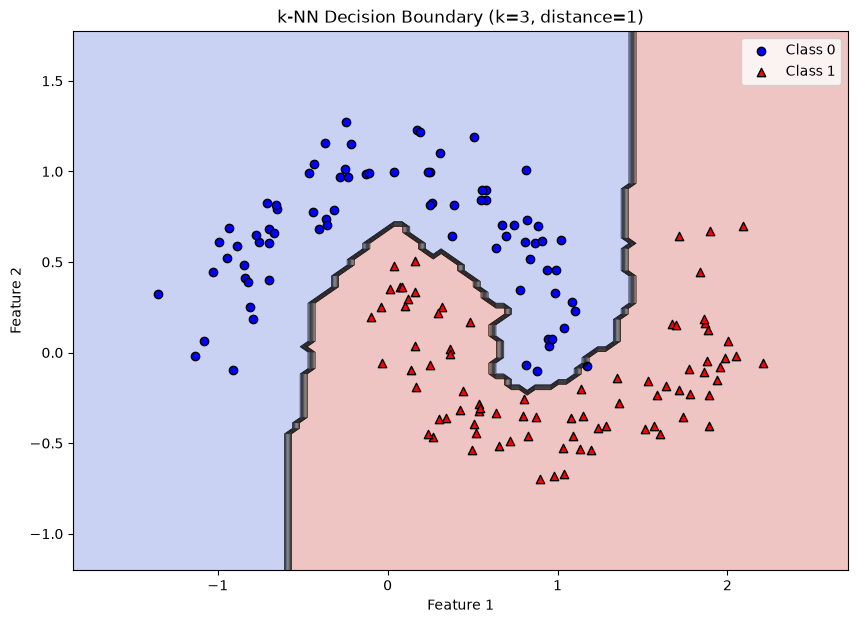

In [30]:
def plot_knn_decision_boundary(X_train, y_train, k, distance_func, resolution=100):
  # Find the boundaries for the graph (add some padding for easier visualization)
  x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
  y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
  xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution),
                        np.linspace(y_min, y_max, resolution))

  # Predict class for each point on the grid
  grid_points = np.c_[xx.ravel(), yy.ravel()]
  predictions = np.array([knn_predict(X_train, y_train, point, k, distance_func)
                          for point in grid_points])
  predictions = predictions.reshape(xx.shape)

  # Plot decision boundary on the graph using the calculated points
  plt.figure(figsize=(10, 7))
  plt.contourf(xx, yy, predictions, alpha=0.3, cmap='coolwarm')
  plt.contour(xx, yy, predictions, colors='k', linewidths=0.5)

  # Plot training points on the graph using different markers/colors for each
  # Get the x and y values for each class, and plot them
  plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
              c='blue', marker='o', edgecolors='k', label='Class 0')
  plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
              c='red', marker='^', edgecolors='k', label='Class 1')

  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')
  plt.title(f'k-NN Decision Boundary (k={k}, distance={distance_func})')
  plt.legend()
  plt.show()

plot_knn_decision_boundary(X_train, y_train, k=3, distance_func=1)

In [36]:
def compute_knn_errors(X, y, k, distance_func):
  n = len(X)

  # Training error: Use the full dataset as the training set to predict
  train_misses = 0
  for i in range(n):
    pred = knn_predict(X, y, X[i], k, distance_func)
    if pred != y[i]:
      train_misses += 1
  train_error = train_misses / n

  # Test error: LOOCV
  test_misses = 0
  for i in range(n):
    # Use record i as testing, and all others as training
    X_train = np.delete(X, i, axis=0)
    y_train = np.delete(y, i)
    pred = knn_predict(X_train, y_train, X[i], k, distance_func)
    if pred != y[i]:
      test_misses += 1
  test_error = test_misses / n

  print(f"k={k}, distance={distance_func}")
  print(f"  Training error: {train_error:.4f} ({train_misses}/{n})")
  print(f"  Test error (LOOCV): {test_error:.4f} ({test_misses}/{n})")
  return train_error, test_error

compute_knn_errors(X, y, k=3, distance_func=1)

k=3, distance=1
  Training error: 0.0050 (1/200)
  Test error (LOOCV): 0.0050 (1/200)


(0.005, 0.005)

Problem 3

In [ ]:
X, y = make_moons(n_samples=200, noise=0.15)
for point in [(0.4, 0.45), (0.08, 0.78), (0.75, -0.15)]:
  for k in [1, 3, 5]:
    for ord in [1,2]:
      print(f"Getting KNN Pred for {point}, k={k}, ord={ord}")
      knn_predict(X_train, y_train, np.array(point), k, ord)

Problem 4

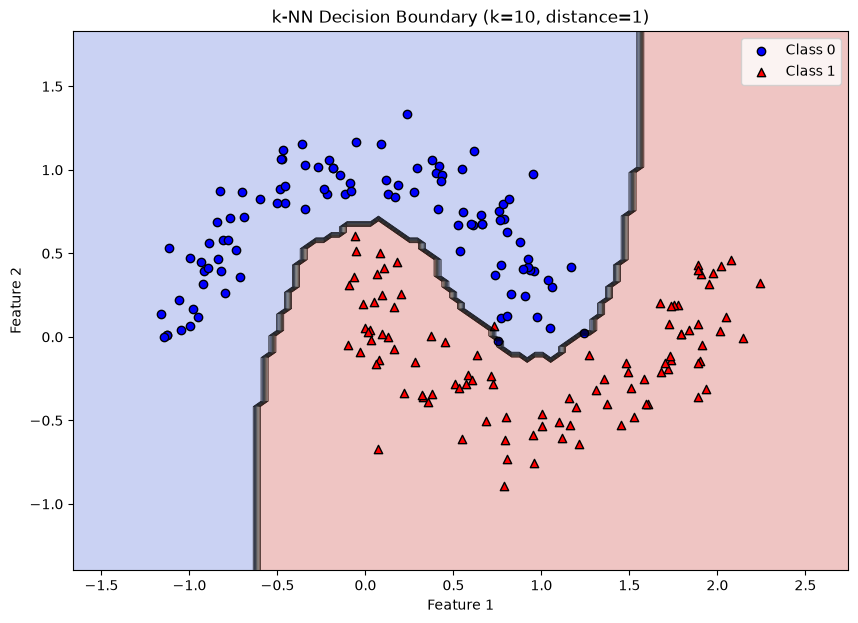

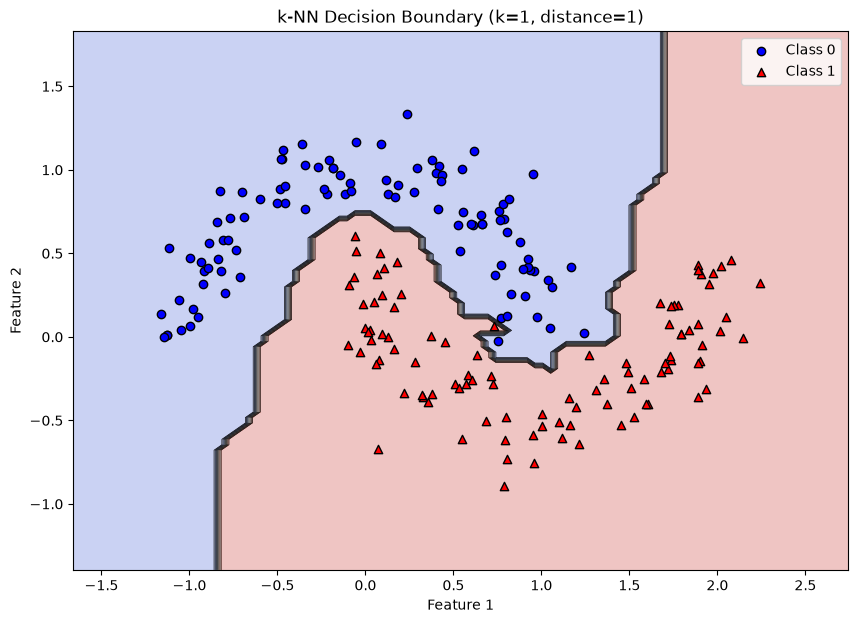

In [33]:
plot_knn_decision_boundary(X, y, 10, distance_func=1)
plot_knn_decision_boundary(X, y, 1, distance_func=1)

Problem 5

In [ ]:
for i in range(1, len(X) + 1):
  train_err, test_err = compute_knn_errors(X, y, i, 2)
  print(f"Cardinality {i} | Train error: {train_err:.4f} | Test error: {test_err:.4f}")

<h1>Neural Network</h1>

In [40]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
  x1, x2, y = training_record
  z = w1 * x1 + w2 * x2 + b
  pred = 1 if z >= 0 else 0
  
  # Update weights and bias using perceptron training rule
  w1 += learning_rate * (y - pred) * x1
  w2 += learning_rate * (y - pred) * x2
  b += learning_rate * (y - pred)
  return w1, w2, b

In [41]:
def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative):
  x, y = training_record
  pred = w * x + b

  # Chain rule: dC/dw = cost_derivative(z, y) * activation_derivative(z) * x
  delta = cost_derivative(pred, y) * activation_derivative(pred)

  # Update weight and bias
  w -= learning_rate * delta * x
  b -= learning_rate * delta
  return w, b

Problem 7

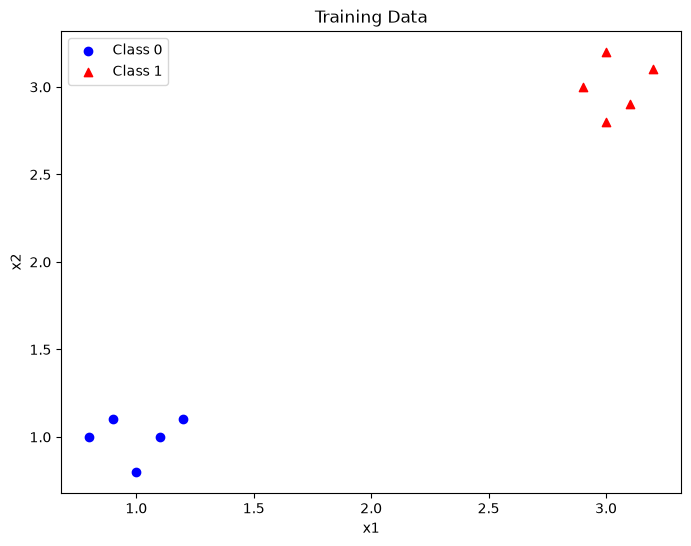

In [47]:
data = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1,
0), (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]

x1 = [d[0] for d in data]
x2 = [d[1] for d in data]
labels = [d[2] for d in data]

plt.figure(figsize=(8, 6))
for cls, color, marker in [(0, 'blue', 'o'), (1, 'red', '^')]:
  plt.scatter([x1[i] for i in range(len(data)) if labels[i] == cls],
              [x2[i] for i in range(len(data)) if labels[i] == cls],
              c=color, marker=marker, label=f'Class {cls}')
  
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Training Data')
plt.legend()
plt.show()

In [ ]:
# Intentionally bad w1, w2, and b
w1, w2, b = -1, -1, 4
learning_rate = 0.1

def plot_perceptron_boundary(data, w1, w2, b, step, error):
  x1 = [d[0] for d in data]
  x2 = [d[1] for d in data]
  labels = [d[2] for d in data]
  
  plt.figure(figsize=(6, 5))
  for cls, color, marker in [(0, 'blue', 'o'), (1, 'red', '^')]:
    plt.scatter([x1[i] for i in range(len(data)) if labels[i] == cls],
                [x2[i] for i in range(len(data)) if labels[i] == cls],
                c=color, marker=marker, edgecolors='k', label=f'Class {cls}')
  
  # Decision boundary: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
  if w2 != 0:
    x_line = np.linspace(0, 4, 100)
    x2_line = -(w1 * x_line + b) / w2
    plt.plot(x_line, x2_line, 'k-', linewidth=2)
  
  plt.xlim(0, 4)
  plt.ylim(0, 4)
  plt.xlabel('x1')
  plt.ylabel('x2')
  plt.title(f'Step {step}: w1={w1:.2f}, w2={w2:.2f}, b={b:.2f}\nError: {error}/{len(data)}')
  plt.legend()
  plt.show()

def compute_perceptron_error(data, w1, w2, b):
  errors = 0
  for x1, x2, y in data:
    pred = 1 if w1 * x1 + w2 * x2 + b >= 0 else 0
    if pred != y:
      errors += 1
  return errors

# Train over multiple epochs, plotting after each epoch
best_w1, best_w2, best_b = w1, w2, b
best_error = len(data)

error = compute_perceptron_error(data, w1, w2, b)
plot_perceptron_boundary(data, w1, w2, b, 'Init', error)

converged = False
for epoch in range(50):
  for record in data:
    w1, w2, b = train_perceptron(record, learning_rate, w1, w2, b)
  
  error = compute_perceptron_error(data, w1, w2, b)
  plot_perceptron_boundary(data, w1, w2, b, f'Epoch {epoch + 1}', error)
  if error < best_error:
    best_error = error
    best_w1, best_w2, best_b = w1, w2, b
  if error == 0:
    converged = True
    break

if not converged:
  print(f"\nBest model: w1={best_w1:.2f}, w2={best_w2:.2f}, b={best_b:.2f}, error={best_error}/{len(data)}")
  plot_perceptron_boundary(data, best_w1, best_w2, best_b, 'Best', best_error)

Problem 9

In [52]:
import random
import pandas as pd

In [53]:
def generate_noisy_data(functions, true_function, x_range, n_samples, epsilon):
  """
  Generate a DataFrame of noisy samples by evaluating each function and the true function at random x values.

  functions: a series of lambdas, each taking a single numerical value
  true_function: a lambda that computes a single numerical value
  x_range: a list of length 2 defining the range of x values to sample from
  n_samples: a positive integer for how many samples to generate
  epsilon: a noise value added to or subtracted from the true value
  """
  rows = []
  for _ in range(n_samples):
    x_val = random.uniform(x_range[0], x_range[1])

    function_results = []
    for function in functions:
      val = function(x_val)
      function_results.append(val)

    true_val = true_function(x_val)
    esp_val = random.choice([-epsilon, epsilon])
    function_results.append(true_val + esp_val)

    rows.append(function_results)

  columns = [f"f{i}" for i in range(len(functions))] + ["y"]
  return pd.DataFrame(rows, columns=columns)

df = generate_noisy_data(
  functions=[lambda x: x],
  true_function=lambda x: 2*x+3,
  x_range=[0,1],
  n_samples=100,
  epsilon=0.1
)

df.head()

,f0,y
0,0.154540,3.409080
1,0.229071,3.558143
2,0.637434,4.374868
3,0.426292,3.952585
4,0.303628,3.507255


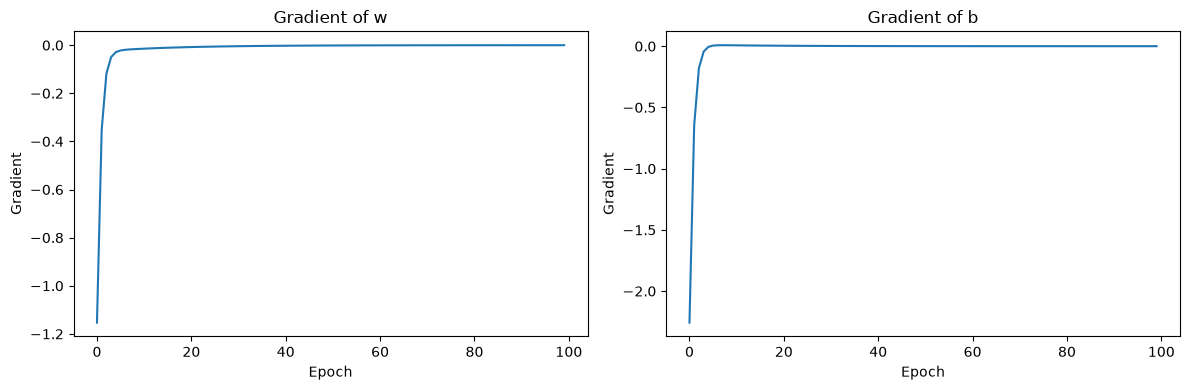

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Activation functions and their derivatives
def sigmoid(z):
  return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(z):
  s = sigmoid(z)
  return s * (1 - s)

def linear(z):
  return z

def linear_derivative(z):
  return 1

def relu(z):
  return max(0, z)

def relu_derivative(z):
  return 1 if z > 0 else 0

# Cost derivatives (dC/da where a = activation output)
def mse_derivative(pred, y):
  return pred - y

def mae_derivative(pred, y):
  return 1 if pred > y else (-1 if pred < y else 0)

# Activation and cost function params
activation_fn = linear
activation_deriv = linear_derivative 
cost_deriv = mse_derivative

# Train params
learning_rate = 0.01
epochs = 100
w = 0.0
b = 0.0

# Extract training data from the DataFrame
x_data = df['f0'].values
y_data = df['y'].values

# Train and record history
w_history = [w]
b_history = [b]
grad_w_history = []
grad_b_history = []

# Train the model
for epoch in range(epochs):
  epoch_grad_w = 0
  epoch_grad_b = 0
  for i in range(len(x_data)):
    record = (x_data[i], y_data[i])
    # Compute gradient before update
    z = w * record[0] + b
    delta = cost_deriv(z, record[1]) * activation_deriv(z)
    epoch_grad_w += delta * record[0]
    epoch_grad_b += delta
    w, b = train_neuron(record, learning_rate, w, b, cost_deriv, activation_deriv)
  
  # Average gradient over all samples for this epoch
  grad_w_history.append(epoch_grad_w / len(x_data))
  grad_b_history.append(epoch_grad_b / len(x_data))
  w_history.append(w)
  b_history.append(b)

# Animation: model learning over epochs
fig, ax = plt.subplots(figsize=(8, 6))
x_plot = np.linspace(x_data.min() - 0.1, x_data.max() + 0.1, 100)

def animate(frame):
  ax.clear()
  ax.scatter(x_data, y_data, c='blue', alpha=0.5, label='Training data')
  ax.plot(x_plot, 2 * x_plot + 3, 'g--', label='True function (2x+3)')
  w_cur = w_history[frame]
  b_cur = b_history[frame]
  y_pred = w_cur * x_plot + b_cur
  ax.plot(x_plot, y_pred, 'r-', linewidth=2, label=f'Model: {w_cur:.2f}x + {b_cur:.2f}')
  ax.set_xlim(x_data.min() - 0.1, x_data.max() + 0.1)
  ax.set_ylim(y_data.min() - 0.5, y_data.max() + 0.5)
  ax.set_xlabel('x')
  ax.set_ylabel('y')
  ax.set_title(f'Epoch {frame}/{epochs}')
  ax.legend(loc='upper left')

ani = FuncAnimation(fig, animate, frames=len(w_history), interval=100, repeat=False)
plt.close(fig)
HTML(ani.to_jshtml())

# --- Gradient plots ---
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(grad_w_history)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Gradient')
ax1.set_title('Gradient of w')
ax2.plot(grad_b_history)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Gradient')
ax2.set_title('Gradient of b')
plt.tight_layout()
plt.show()